[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_safe_haven/BA_L2_safe_haven.ipynb)

# BA_L2_safe_haven: Average Returns on the Worst Equity Days

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Mean daily return of the S&P 500, Bitcoin, Ethereum and gold on the worst 5% of S&P 500 days, with 95% confidence intervals, on the days common to all four assets, 2018 to 18 September 2026.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

Baur and Lucey (2010) call an asset a **safe haven** if it is uncorrelated or negatively correlated with equities
in extreme market stress. The check here is simpler: take the set $\mathcal{S}$ of the worst 5% of S&P 500 days and
the mean return of asset $x$ on those days, with a 95% confidence interval (CI),

$$\bar x_{\mathcal{S}} = \frac{1}{n_{\mathcal{S}}}\sum_{t \in \mathcal{S}} x_t, \qquad \bar x_{\mathcal{S}} \pm 1.96\,\frac{s_{\mathcal{S}}}{\sqrt{n_{\mathcal{S}}}}.$$

Prices are joined on the days common to all four assets, then daily log returns in percent are computed,
1 January 2018 to 18 September 2026.

**How to read the chart.** A bar below zero whose interval excludes zero means the asset lost on average when
equities were under stress. Not rejecting a zero mean does not show that the mean is non-negative.

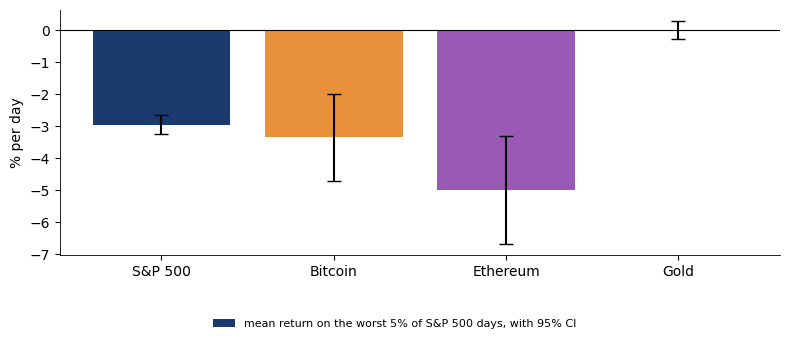

In [5]:
px = pd.concat({'S&P 500': prices('GSPC.INDX'), 'Bitcoin': prices('BTC-USD.CC'), 'Ethereum': prices('ETH-USD.CC'),
                'Gold': prices('XAUUSD.FOREX')}, axis=1).dropna()
X = (100 * np.log(px).diff()).dropna().loc['2018-01-01':]
thr = X['S&P 500'].quantile(0.05)
S = X[X['S&P 500'] <= thr]
rows = {}
for k in ['S&P 500', 'Bitcoin', 'Ethereum', 'Gold']:
    m_, s_, n_ = S[k].mean(), S[k].std(), len(S)
    rows[k] = {'mean on worst days (%)': m_, '95% CI half-width': 1.96 * s_ / np.sqrt(n_),
               't': m_ / (s_ / np.sqrt(n_)), 'mean on all days (%)': X[k].mean()}
SH = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(SH.index, SH['mean on worst days (%)'], yerr=SH['95% CI half-width'], color=[BLUE, BTC, ETH, GOLD], capsize=5,
       label='mean return on the worst 5% of S&P 500 days, with 95% CI')
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('% per day')
slide_legend(fig, 0.12, ncol=1)
save_fig(fig, 'ba_l2_safe_haven')

In [6]:
print(f'Common days: {len(X):,}; worst 5% of S&P 500 days: {len(S)} days with a return of {thr:.2f}% or less')
print(SH.round(3).to_string())

Common days: 2,190; worst 5% of S&P 500 days: 110 days with a return of -1.77% or less
          mean on worst days (%)  95% CI half-width       t  mean on all days (%)
S&P 500                   -2.958              0.292 -19.825                 0.048
Bitcoin                   -3.357              1.366  -4.818                 0.078
Ethereum                  -4.995              1.688  -5.798                 0.057
Gold                       0.012              0.281   0.085                 0.055
